# Detecção de Evasão no Ensino Superior

Este notebook apresenta, de forma estática, um MVP para identificar estudantes com risco de evasão. A análise compara três momentos de previsão: **matrícula**, **após o 1º semestre** e **após o 2º semestre**.

A classe `Enrolled` é removida porque representa uma trajetória ainda não definida. O alvo passa a ser binário: `1` para evasão e `0` para graduação.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42
DATA_PATH = Path("data") / "data.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH, sep=";")
df.columns = df.columns.str.replace("\t", " ", regex=False).str.strip()
print(f"Dimensões originais: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Colunas normalizadas: {list(df.columns)}")

Dimensões originais: 4424 linhas x 37 colunas
Colunas normalizadas: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', '

In [5]:
if "Target" not in df.columns:
    raise KeyError("A coluna obrigatória 'Target' não foi encontrada.")

df = df.loc[df["Target"].isin(["Dropout", "Graduate"])].copy()
df["Alvo"] = df["Target"].map({"Dropout": 1, "Graduate": 0}).astype("int8")
df = df.drop(columns="Target")

features_matricula = [
    col for col in df.columns
    if col not in ["Alvo"] and "1st sem" not in col.lower() and "2nd sem" not in col.lower()
]
features_1o_semestre = [
    col for col in df.columns
    if col != "Alvo" and "2nd sem" not in col.lower()
]
features_2o_semestre = [col for col in df.columns if col != "Alvo"]

cenarios = {
    "Matrícula": features_matricula,
    "1º semestre": features_1o_semestre,
    "2º semestre": features_2o_semestre,
}

print(f"Registros definitivos: {len(df)}")
print(f"Evasão: {df['Alvo'].sum()} | Não evasão: {(df['Alvo'] == 0).sum()}")
for nome, features in cenarios.items():
    print(f"{nome}: {len(features)} variáveis")

Registros definitivos: 3630
Evasão: 1421 | Não evasão: 2209
Matrícula: 24 variáveis
1º semestre: 30 variáveis
2º semestre: 36 variáveis


## 1. Dashboard estático: visão geral da base

Os gráficos abaixo são gerados no próprio notebook e constituem uma apresentação estática dos resultados.

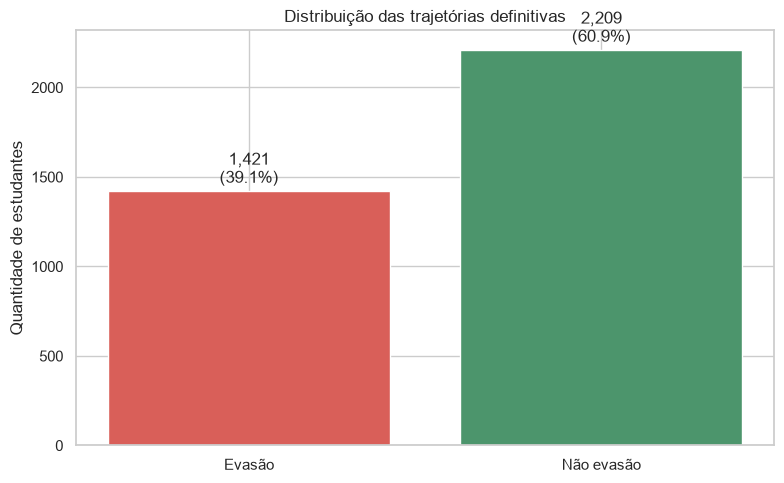

,Quantidade,Percentual (%)
Alvo,,
Evasão,1421,39.15
Não evasão,2209,60.85


In [6]:
contagem = df["Alvo"].map({0: "Não evasão", 1: "Evasão"}).value_counts().reindex(["Evasão", "Não evasão"])
percentual = contagem / contagem.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(contagem.index, contagem.values, color=["#d95f59", "#4c956c"])
ax.set_title("Distribuição das trajetórias definitivas")
ax.set_ylabel("Quantidade de estudantes")
ax.set_xlabel("")
for bar, qtd, pct in zip(bars, contagem, percentual):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
            f"{qtd:,}\n({pct:.1f}%)", ha="center", va="bottom")
plt.tight_layout()
plt.show()

pd.DataFrame({"Quantidade": contagem, "Percentual (%)": percentual.round(2)})

## 2. Correlações no cenário do 1º semestre

A correlação é usada como análise exploratória, não como prova de causalidade. Variáveis com maior associação devem ser interpretadas junto com o contexto acadêmico.

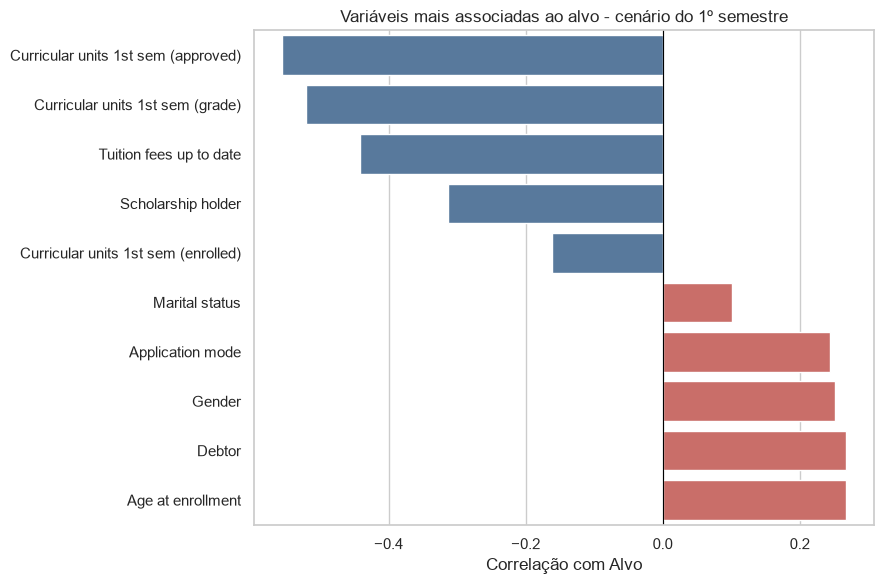

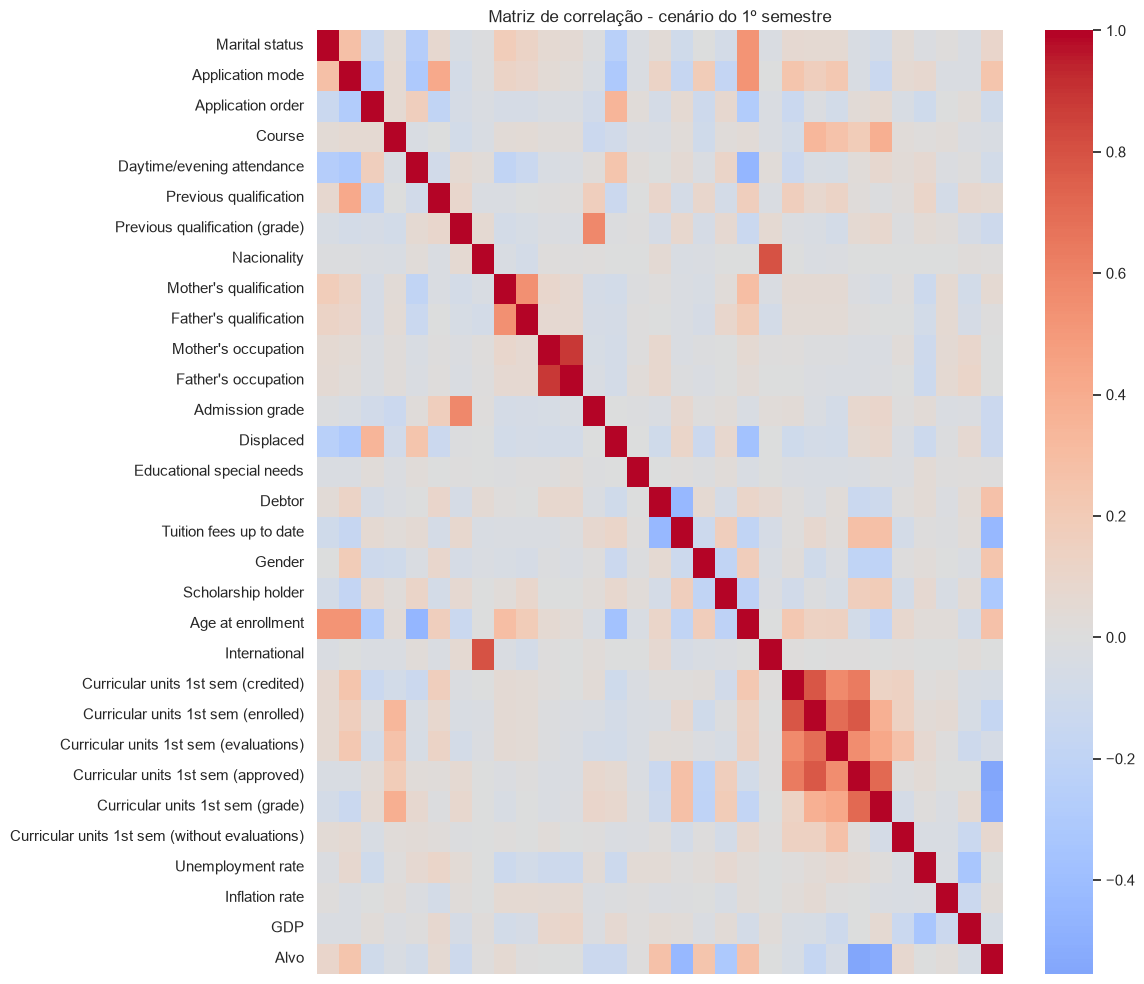

In [7]:
correlacoes = df[features_1o_semestre + ["Alvo"]].corr(numeric_only=True)["Alvo"].drop("Alvo").sort_values()
top_correlacoes = pd.concat([correlacoes.head(5), correlacoes.tail(5)]).sort_values()

plt.figure(figsize=(9, 6))
sns.barplot(x=top_correlacoes.values, y=top_correlacoes.index,
            hue=top_correlacoes.values > 0, legend=False,
            palette={True: "#d95f59", False: "#4c78a8"})
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Variáveis mais associadas ao alvo - cenário do 1º semestre")
plt.xlabel("Correlação com Alvo")
plt.ylabel("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 10))
sns.heatmap(df[features_1o_semestre + ["Alvo"]].corr(numeric_only=True),
            cmap="coolwarm", center=0, xticklabels=False, yticklabels=True)
plt.title("Matriz de correlação - cenário do 1º semestre")
plt.tight_layout()
plt.show()

## 3. Treinamento e avaliação

O conjunto de teste é estratificado e o `StandardScaler` é ajustado somente nos dados de treino. O `class_weight='balanced'` aumenta a atenção dada à classe minoritária.

In [8]:
modelos = {
    "Regressão Logística": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "Árvore de Decisão": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, max_depth=8),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=300,
                                              random_state=RANDOM_STATE, n_jobs=-1),
}

resultados = []
artefatos = {}
y = df["Alvo"]

for nome_cenario, features in cenarios.items():
    X = df[features].apply(pd.to_numeric, errors="raise")
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
    )
    scaler = StandardScaler()
    X_treino_escalado = scaler.fit_transform(X_treino)
    X_teste_escalado = scaler.transform(X_teste)

    for nome_modelo, modelo_base in modelos.items():
        modelo = modelo_base.__class__(**modelo_base.get_params())
        modelo.fit(X_treino_escalado, y_treino)
        previsoes = modelo.predict(X_teste_escalado)
        resultados.append({
            "Cenário": nome_cenario,
            "Modelo": nome_modelo,
            "Precision (evasão)": precision_score(y_teste, previsoes, zero_division=0),
            "Recall (evasão)": recall_score(y_teste, previsoes, zero_division=0),
            "F1 (evasão)": f1_score(y_teste, previsoes, zero_division=0),
        })
        artefatos[(nome_cenario, nome_modelo)] = {
            "modelo": modelo, "features": features, "y_teste": y_teste,
            "previsoes": previsoes, "matriz": confusion_matrix(y_teste, previsoes),
        }

resultados_df = pd.DataFrame(resultados).sort_values(["Cenário", "Recall (evasão)"], ascending=[True, False])
resultados_df.style.format({
"Precision (evasão)": "{:.3f}", "Recall (evasão)": "{:.3f}", "F1 (evasão)": "{:.3f}"
})

,Cenário,Modelo,Precision (evasão),Recall (evasão),F1 (evasão)
3,1º semestre,Regressão Logística,0.854,0.866,0.860
5,1º semestre,Random Forest,0.867,0.840,0.853
4,1º semestre,Árvore de Decisão,0.840,0.786,0.812
6,2º semestre,Regressão Logística,0.879,0.904,0.891
8,2º semestre,Random Forest,0.908,0.885,0.897
7,2º semestre,Árvore de Decisão,0.860,0.847,0.853
0,Matrícula,Regressão Logística,0.653,0.732,0.690
2,Matrícula,Random Forest,0.708,0.723,0.715
1,Matrícula,Árvore de Decisão,0.650,0.702,0.675


,Precision (evasão),Recall (evasão),F1 (evasão)
Cenário,,,
1º semestre,0.866828,0.840376,0.853397
2º semestre,0.908434,0.884977,0.896552
Matrícula,0.708046,0.723005,0.715447


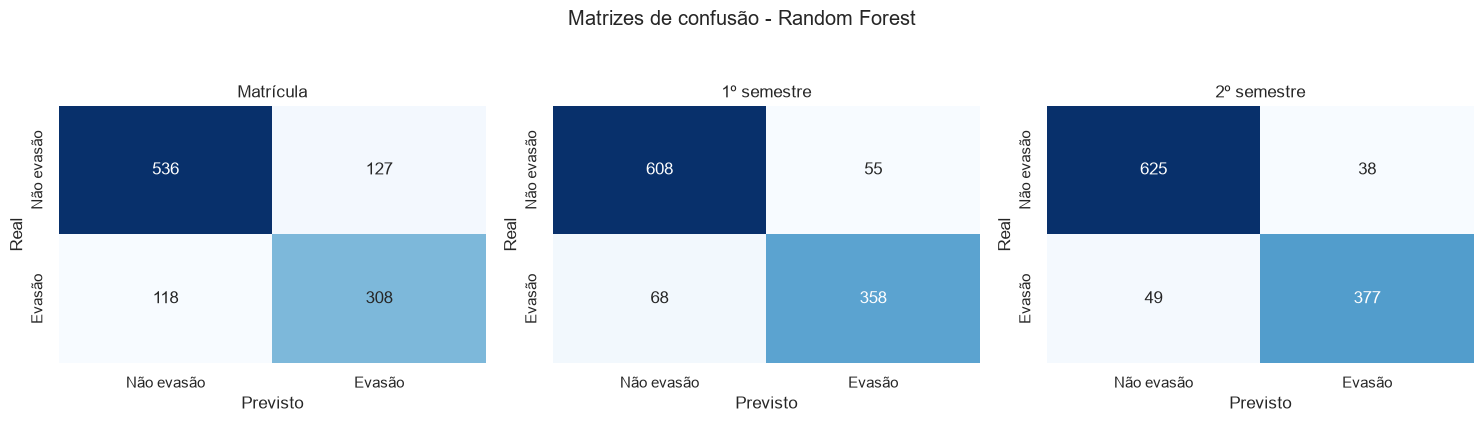

In [9]:
rf_resultados = resultados_df[resultados_df["Modelo"] == "Random Forest"].set_index("Cenário")
display(rf_resultados[["Precision (evasão)", "Recall (evasão)", "F1 (evasão)"]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nome_cenario in zip(axes, cenarios):
    matriz = artefatos[(nome_cenario, "Random Forest")]["matriz"]
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Não evasão", "Evasão"], yticklabels=["Não evasão", "Evasão"])
    ax.set_title(nome_cenario)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
fig.suptitle("Matrizes de confusão - Random Forest", y=1.05)
plt.tight_layout()
plt.show()

## 4. Explicabilidade e conclusão

A importância das variáveis indica quais informações mais contribuíram para as decisões do Random Forest no cenário do 1º semestre. Isso apoia a priorização de ações da coordenação, mas não substitui a avaliação humana do estudante.

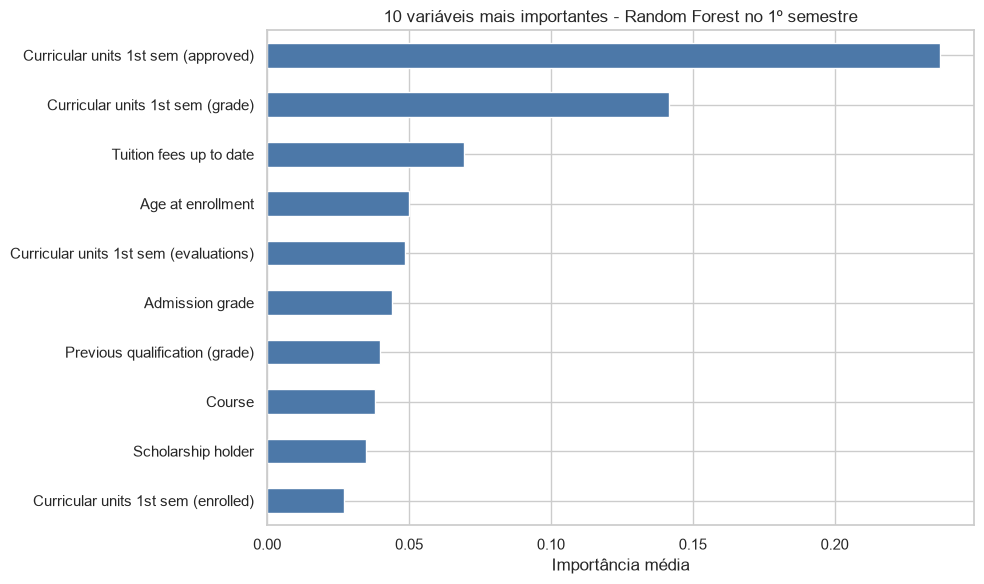

Melhor recall de evasão do Random Forest: 2º semestre (0.885)

Interpretação: o recall deve ser priorizado porque falsos negativos representam estudantes em risco que não receberiam atenção.


In [10]:
artefato_rf = artefatos[("1º semestre", "Random Forest")]
importancias = pd.Series(artefato_rf["modelo"].feature_importances_, index=artefato_rf["features"])
importancias = importancias.sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(10, 6))
importancias.plot(kind="barh", color="#4c78a8")
plt.title("10 variáveis mais importantes - Random Forest no 1º semestre")
plt.xlabel("Importância média")
plt.ylabel("")
plt.tight_layout()
plt.show()

melhor = rf_resultados["Recall (evasão)"].idxmax()
print(f"Melhor recall de evasão do Random Forest: {melhor} ({rf_resultados.loc[melhor, 'Recall (evasão)']:.3f})")
print("\nInterpretação: o recall deve ser priorizado porque falsos negativos representam estudantes em risco que não receberiam atenção.")